## Data loading & Integrity Checks
First, we import the data frames and check whether the data is intact, if there are any discrepancies, errors, etc.

**Data fetching** is done outside this notebook by two scripts, which must be run first:
- `traffic_data_import.py`: downloads accidents, killed and injured from the ISTAT SDMX API to  `traffic_raw.csv`
- `area_data_import.py`: downloads the yearly municipality registry from SITUAS (exports and join each year from 2001 to 2024) to `area_raw.csv`

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from scipy.cluster.vq import kmeans2

In [ ]:
# traffic_raw contains the main data
# downloaded from: "https://esploradati.istat.it/SDMXWS/rest/data/41_983"
# via script: 'traffic_data_import.py'
traffic_raw = pd.read_csv('../raw/traffic_raw.csv')
# are_raw contains some useful data on the areas
# as downloaded from: https://situas.istat.it/ShibO2Module/api/Report/Spool/2001-12-31/74?&pdoctype=CSV
# from the url we can see that there is date parameter, that I have manipulated to get the same year timeframe that the other data has (2001-2024)
# via script: 'area_data_import.py'
# the cvs uses `;` as separators, as often happens in some eu countries
area_raw = pd.read_csv('../raw/area_raw.csv', delimiter=';')

In [46]:
# first look at the raw traffic data: columns, types, missing values
traffic_raw.info()
traffic_raw.head()

<class 'pandas.DataFrame'>
RangeIndex: 573552 entries, 0 to 573551
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   DATAFLOW          573552 non-null  str    
 1   FREQ              573552 non-null  str    
 2   REF_AREA          573552 non-null  int64  
 3   DATA_TYPE         573552 non-null  str    
 4   RESULT            573552 non-null  str    
 5   TIME_PERIOD       573552 non-null  int64  
 6   OBS_VALUE         573552 non-null  int64  
 7   OBS_STATUS        0 non-null       float64
 8   NOTE_DS           0 non-null       float64
 9   NOTE_REF_AREA     0 non-null       float64
 10  NOTE_DATA_TYPE    0 non-null       float64
 11  NOTE_RESULT       0 non-null       float64
 12  NOTE_TIME_PERIOD  0 non-null       float64
 13  BASE_PER          0 non-null       float64
 14  UNIT_MEAS         0 non-null       float64
 15  UNIT_MULT         0 non-null       float64
dtypes: float64(9), int64(3), str(4)

,DATAFLOW,FREQ,REF_AREA,DATA_TYPE,RESULT,TIME_PERIOD,OBS_VALUE,OBS_STATUS,NOTE_DS,NOTE_REF_AREA,NOTE_DATA_TYPE,NOTE_RESULT,NOTE_TIME_PERIOD,BASE_PER,UNIT_MEAS,UNIT_MULT
0,IT1:41_983(1.0),A,1001,KILLINJ,F,2001,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IT1:41_983(1.0),A,1001,KILLINJ,F,2002,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IT1:41_983(1.0),A,1001,KILLINJ,F,2003,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,IT1:41_983(1.0),A,1001,KILLINJ,F,2004,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IT1:41_983(1.0),A,1001,KILLINJ,F,2005,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [47]:
# we can see that ther are a lot of fully null columns, so we can drop those
traffic_raw.dropna(axis=1, inplace=True)
# also some columns are not needed
traffic_raw = traffic_raw[[
            #'DATAFLOW' is not needed because it has the same value all across (it identify the data flow)
            #'FREQ' is not needed because it has the same value all across (the frequency of the misuration, which is yearly)
            'REF_AREA', 'DATA_TYPE', 'RESULT', 'TIME_PERIOD', 'OBS_VALUE']]

In [48]:
# summary statistics to spot anomalies (e.g. very high OBS_VALUE)
traffic_raw.describe()

,REF_AREA,TIME_PERIOD,OBS_VALUE
count,573552.000000,573552.000000,573552.000000
mean,44528.628771,2012.340541,20.207603
std,32093.886203,6.859876,245.813966
min,1001.000000,2001.000000,0.000000
25%,16137.000000,2006.000000,0.000000
50%,38012.500000,2012.000000,1.000000
75%,71052.000000,2018.000000,8.000000
max,111107.000000,2024.000000,30254.000000


We can see apparently a very high value in OBS_VALUE. If checked with `traffic_raw.sort_values(by=['OBS_VALUE'], ascending=False).head(10)` we can see that there are at least 10 mostly in the same `REF_ARE` over the years.  
  
Probably it's because of the high density of the area, or likely also the **specific DATA_TYPE and RESULT combo (KILLINJ + F), which identifies the injured** (so we can espect it to be higher than killing).
Let's just make a mental note of that, we might need to pivot to better understand the data.  
  
The `'DATA_TYPE'` column has 2 options: `KILLINJ` and `ROADACC`, which would be (1) the killed and injuried and (2) the road accidents respectively. The kills and injuries are further divided by the `'RESULT'` column between `M`, `F`, while the accidents have a code `9`, because probably the column isn't relevant to that category.

Accidents counts only road accidents with injuries to people: [ISTAT definition as found (**Be warned:** source is a pdf file)](https://www.istat.it/it/files/2012/10/nota_metodologica_e-_-glossario_anno_2011.pdf): crashes with property damage only are not recorded. `injured` and `killed` count people, so one accident can produce several victims.  
  
The `'OBS_VALUE'` column has the value associated with the events of the other two columns. 

In [49]:
# lets create the colum "event" combining 'DATA_TYPE' and 'RESULT' and drop the old columns
traffic_raw['EVENT'] = traffic_raw['DATA_TYPE'] + "-" + traffic_raw['RESULT']
traffic_raw.drop(['DATA_TYPE', 'RESULT'], axis=1, inplace=True)
# now we can pivot
traffic_raw = traffic_raw.pivot_table(
    index=['REF_AREA', 'TIME_PERIOD'],
    columns='EVENT',
    values='OBS_VALUE',
    aggfunc='sum'
    ).reset_index()
# and just to make it more readable, rename the column names
traffic_raw = traffic_raw.rename(columns={
    'REF_AREA' : 'area_code',
    'TIME_PERIOD' : 'year',
    'KILLINJ-F' : 'injured',
    'KILLINJ-M' : 'killed',
    'ROADACC-9' : 'accidents'
})

In [50]:
# fast check of info()
area_raw.info()
area_raw.head()

<class 'pandas.DataFrame'>
RangeIndex: 192731 entries, 0 to 192730
Data columns (total 16 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   Codice Ripartizione geografica  192731 non-null  int64  
 1   Codice Regione                  192731 non-null  int64  
 2   Codice Provincia/Uts            192731 non-null  int64  
 3   Codice Comune (alfanumerico)    192731 non-null  int64  
 4   Codice Comune (numerico)        192731 non-null  int64  
 5   Comune                          192707 non-null  str    
 6   Comune (dizione straniera)      2911 non-null    str    
 7   Sigla automobilistica           190523 non-null  str    
 8   Capoluogo di Provincia/Uts      192731 non-null  int64  
 9   Capoluogo di Regione            192731 non-null  int64  
 10  Popolazione legale              192722 non-null  float64
 11  Anno Censimento                 192731 non-null  int64  
 12  Superficie (Kmq)           

,Codice Ripartizione geografica,Codice Regione,Codice Provincia/Uts,Codice Comune (alfanumerico),Codice Comune (numerico),Comune,Comune (dizione straniera),Sigla automobilistica,Capoluogo di Provincia/Uts,Capoluogo di Regione,Popolazione legale,Anno Censimento,Superficie (Kmq),Anno (Superficie),Popolazione residente,Anno (Popolazione residente)
0,1,1,201,1001,1001,Agliè,NaN,TO,0,0,2574.0,2001,"13,1462",2001,2557,2001
1,1,1,201,1002,1002,Airasca,NaN,TO,0,0,3554.0,2001,"15,7393",2001,3543,2001
2,1,1,201,1003,1003,Ala di Stura,NaN,TO,0,0,479.0,2001,"46,3315",2001,480,2001
3,1,1,201,1004,1004,Albiano d'Ivrea,NaN,TO,0,0,1696.0,2001,"11,7315",2001,1687,2001
4,1,1,201,1005,1005,Alice Superiore,NaN,TO,0,0,616.0,2001,"7,3796",2001,619,2001


We can see that column 6 is mostly null, plus there are some null values on column 5 (probably unnamed area codes?). We can keep the data since it has an area code, later we'll see if there are issues in data visualization.  

We also see that column 7 is a deprecated way to identify provinces, so we can drop it, plus column 10 is the census which is data only up to 2017 since from that date Italy switched to a different method so we can also drop 10 and 11 (plus residency is more relevant).

In [51]:
area_raw = area_raw[[
    #'Codice Ripartizione geografica',
    'Codice Regione',
    'Codice Provincia/Uts', 'Codice Comune (alfanumerico)',
    # 'Codice Comune (numerico)',
    'Comune',
    # 'Comune (dizione straniera)', 'Sigla automobilistica', 
    'Capoluogo di Provincia/Uts', 'Capoluogo di Regione',
    # 'Popolazione legale', 'Anno Censimento',
    'Superficie (Kmq)',
    'Popolazione residente',
    'Anno (Popolazione residente)'
    ]]
# lets rename the others for ease of use
area_raw = area_raw.rename(columns={
    'Codice Regione' : 'region_code',
    'Codice Provincia/Uts' : 'province_code',
    'Codice Comune (alfanumerico)' : 'area_code',
    'Comune' : 'area_name',
    'Capoluogo di Provincia/Uts' : 'is_province_capital',
    'Capoluogo di Regione' : 'is_region_capital',
    'Superficie (Kmq)' : 'surface',
    'Popolazione residente' : 'residents',
    'Anno (Popolazione residente)' : 'year'
    })

Finally we can see that some data need to be cast to the correct dtype.

In [52]:
# lets cast the correct data types
area_raw['is_province_capital'] = area_raw['is_province_capital'].astype(bool)
area_raw['is_region_capital'] = area_raw['is_region_capital'].astype(bool)

# to be correctely read as float we have make some replacement to the surface before casting to float
area_raw['surface'] = area_raw['surface']\
    .str.replace(".","", regex=False) \
    .str.replace(",",".", regex=False)\
    .astype(float)
area_raw.info()

area_raw.describe()

<class 'pandas.DataFrame'>
RangeIndex: 192731 entries, 0 to 192730
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   region_code          192731 non-null  int64  
 1   province_code        192731 non-null  int64  
 2   area_code            192731 non-null  int64  
 3   area_name            192707 non-null  str    
 4   is_province_capital  192731 non-null  bool   
 5   is_region_capital    192731 non-null  bool   
 6   surface              192731 non-null  float64
 7   residents            192731 non-null  int64  
 8   year                 192731 non-null  int64  
dtypes: bool(2), float64(1), int64(5), str(1)
memory usage: 10.7 MB


,region_code,province_code,area_code,surface,residents,year
count,192731.000000,192731.000000,192731.000000,192731.000000,1.927310e+05,192731.000000
mean,8.604615,77.421121,44588.017314,37.615814,7.370508e+03,2012.434523
std,6.369382,80.270723,32162.005240,50.283729,4.083646e+04,6.911479
min,1.000000,2.000000,1001.000000,0.120600,2.800000e+01,2001.000000
25%,3.000000,19.000000,16134.000000,11.295200,1.016000e+03,2006.000000
50%,7.000000,56.000000,38018.000000,22.038300,2.413000e+03,2012.000000
75%,15.000000,94.000000,71060.000000,43.682500,6.064000e+03,2018.000000
max,20.000000,292.000000,111107.000000,1288.187500,2.820219e+06,2024.000000


### Merging DataFrames & Final Cleanup Notes

Let's merge the dataframes so we can make some other useful columns.

In [53]:
# we must merge on both year and area_code
traffic = pd.merge(traffic_raw, area_raw, on=['area_code', 'year'], how='left')
traffic.info()

<class 'pandas.DataFrame'>
RangeIndex: 191184 entries, 0 to 191183
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   area_code            191184 non-null  int64  
 1   year                 191184 non-null  int64  
 2   injured              191184 non-null  int64  
 3   killed               191184 non-null  int64  
 4   accidents            191184 non-null  int64  
 5   region_code          190900 non-null  float64
 6   province_code        190900 non-null  float64
 7   area_name            190876 non-null  str    
 8   is_province_capital  190900 non-null  object 
 9   is_region_capital    190900 non-null  object 
 10  surface              190900 non-null  float64
 11  residents            190900 non-null  float64
dtypes: float64(4), int64(5), object(2), str(1)
memory usage: 17.5+ MB


In [54]:
# column 5 and 6 have been recast as float (some NaNs are at fault)
# we must change to the nullable integer dtype
traffic[['region_code', 'province_code']] = traffic[['region_code', 'province_code']].astype('Int64')
# column 8 and 9 have been recast as object (some NaNs are at fault)
# we can assume that if there is NaN they are not province/region capital
traffic['is_province_capital'] = traffic['is_province_capital'].fillna(False).astype(bool)
traffic['is_region_capital'] = traffic['is_region_capital'].fillna(False).astype(bool)

In [55]:
# final integrity check
print(f"Shape: {traffic.shape[0]}")
print(f"Unique 'area names': {traffic['area_name'].nunique()}")
print(f"There are duplicates combo of area codes and year? {traffic.duplicated(subset=['year', 'area_code']).any()}")

# let's check for errors in the accident reports:
print(f"There are {len(traffic[(traffic['accidents'] == 0) & ((traffic['injured'] > 0) | (traffic['killed'] > 0))])} errors in accident reporting")
print("NaNs:")
print(traffic[['accidents', 'injured', 'killed', 'residents']].isnull().sum())

# residents has some NaN, that has to be because probably some area_code are no more in existance
print(f"There are {len(traffic[(traffic['residents'].isnull()) & (traffic['accidents'] == 0)])} rows without accidents and population records")

# since injured and killed are the nr of people, while accidents is a count of event where people have been at least injured
print(f"There are {(traffic['injured'] + traffic['killed'] < traffic['accidents']).sum()} anomalies within the accidents column")

Shape: 191184
Unique 'area names': 8249
There are duplicates combo of area codes and year? False
There are 0 errors in accident reporting
NaNs:
accidents      0
injured        0
killed         0
residents    284
dtype: int64
There are 55 rows without accidents and population records
There are 0 anomalies within the accidents column


In [56]:
# it is safe to drop the values that have both NaN redicents and 0 accidents
traffic = traffic[~(traffic['residents'].isna() & (traffic['accidents'] == 0))].copy()

**Note on missing population data:** after the merge, 284 rows have no population figure. 55 of them also have zero accidents, so they were dropped. The remaining 229 rows have accidents but no residents, probably because the area code no longer existed in the registry for that year. They are kept so national and regional accident totals stay complete, but they slightly inflate per-capita rates in aggregated tables, since their accidents count while their population does not. The effect should be negligible.

In [57]:
# summary of the main numeric columns after cleaning
traffic[[
    #'area_code', 'year',
    'injured', 'killed', 'accidents',
    # 'region_code', 'province_code', 'area_name', 'is_province_capital', 'is_region_capital',
    'surface', 'residents']].describe()

,injured,killed,accidents,surface,residents
count,191129.000000,191129.000000,191129.000000,190900.000000,1.909000e+05
mean,35.102083,0.533378,25.004793,37.700705,7.423751e+03
std,338.158002,2.783891,257.556674,50.401151,4.102415e+04
min,0.000000,0.000000,0.000000,0.120600,2.800000e+01
25%,1.000000,0.000000,1.000000,11.328000,1.032000e+03
50%,5.000000,0.000000,3.000000,22.131900,2.442000e+03
75%,18.000000,0.000000,12.000000,43.808300,6.115250e+03
max,30254.000000,363.000000,23135.000000,1288.187500,2.820219e+06


## Metric Definitions
We need to define some new metrics to better understand the data.
* A density rate it's a given: residents / surface.
* Some sort of "accident rate" should be useful. This kind of stats usually goes for the "accidents over 100k/10k/1k" but since we'll be looking at small municipalities, 'accidents over 1000 residents' should suffice.
* While `accidents` refers to the events, the `injured` column is a count of people injured, so there can be multiple people injured in a single event. So we can just have injured per events as a mean value, not a share.
* Same reasoning as above, with `killed`. We can use killed per event, but the numbers will be pretty small. ISTAT uses sometimes 'deaths per 100 accidents' in these cases.
* While it will be useful to highlight the most recent years, there might be some trouble using recent years. The dataset is from 2001-2024 so last 3/5 years will include the 2020-2021 pandemic. Probably is better to stick to the last 3 years to exclude the pandemic effect, when it is required to look at more recent years.

In [58]:
# lets make some functions to manage what we have ahead

def add_metrics(df, n_years=1):
    # this func adds the metrics we need to a specific dataframe
    df = df.copy()
    df['density'] = df['residents'] / df['surface']
    df['accidents_per_1000people'] = df['accidents'] / n_years / df['residents'] * 1000
    df['injured_per_accident'] = df['injured'] / df['accidents']
    df['killed_per_100accidents'] = df['killed'] / df['accidents'] * 100
    
    # added derived safety metrics, replacing inf with NaN.
    return df.replace([np.inf, -np.inf], np.nan)

# now we define the aggregate function that will make our dataframes better usable for further investigations:

# core function
def aggregate(df, group_by, residents_agg='mean', surface_agg='first'):
    # this establish the core aggregation: sum counts, mean residents (by default), first surface (by default)
    return (df.groupby(list(group_by), as_index=False)
            .agg(accidents=('accidents', 'sum'),
                 injured=('injured', 'sum'),
                 killed=('killed', 'sum'),
                 residents=('residents', residents_agg),
                 surface=('surface', surface_agg)))


# func 1
def aggregate_yearly(df, group_by=(), exclude_2020=True):
    # this one aggregates per-year metrics for each group
    keys = list(group_by) + ['year']
    mask = df['year'] != 2020 if exclude_2020 else pd.Series(True, index=df.index)
    output = aggregate(df[mask], keys, residents_agg='sum', surface_agg='sum')
    return add_metrics(output, n_years=1)

# func 2
def aggregate_period(df, start_year, end_year, exclude_2020=True,
                     group_by=('area_code', 'area_name', 'province_code', 'region_code',
                               'is_province_capital', 'is_region_capital')):
    # this one aggregates metrics over a multi-year window, optionally excluding 2020
    
    if start_year > end_year: # checks if the period is valid
        raise ValueError('start_year must be <= end_year')

    mask = df['year'].between(start_year, end_year) # this mask to show just the years we need
    if exclude_2020:
        mask &= df['year'] != 2020

    masked_df = df[mask]
    output = aggregate(masked_df, group_by)

    # n_years reflects only years actually present in the data
    n_years = masked_df.groupby(list(group_by))['year'].nunique()
    output = output.merge(n_years.rename('n_years').reset_index(), on=list(group_by))

    output = add_metrics(output, n_years=output['n_years'])

    excluded = exclude_2020 and start_year <= 2020 <= end_year
    output['period'] = f'{start_year}-{end_year}' + (' excl. 2020' if excluded else '')
    return output

## National and regional trends
* Are accidents declining over time at national level?
    * Is the trend still visibile if we drop 2020?
* Is the same true at regional level? There is a north/south divide?

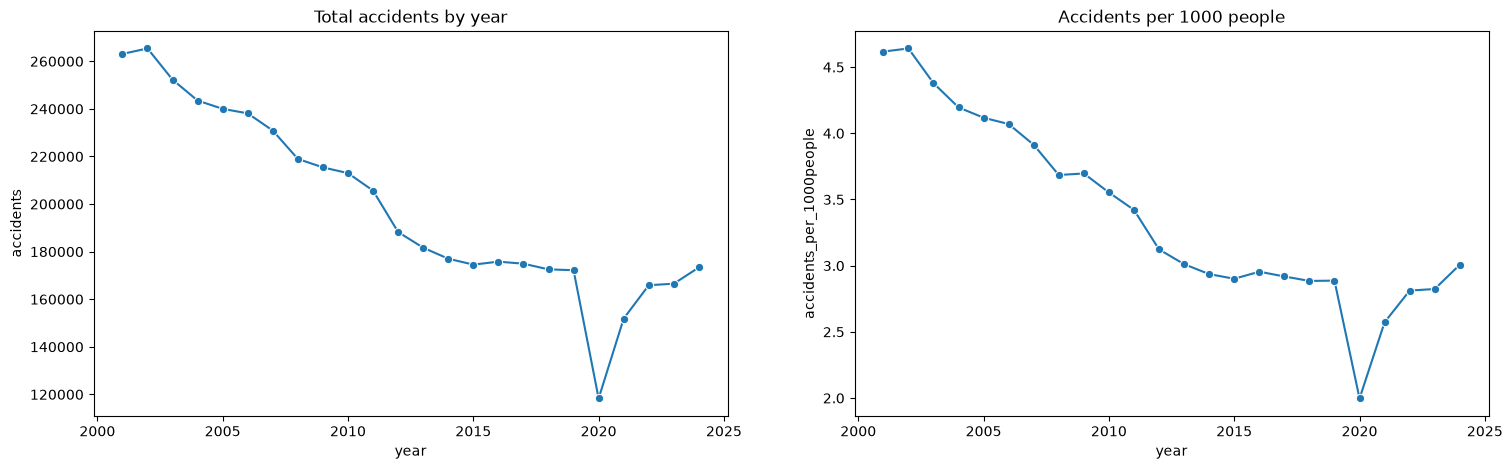

In [59]:
# lets explore the national data
national  = aggregate_yearly(traffic, exclude_2020=False)
# we can exclude or include 2020 but the line won't change too much, besides the 'dip' on the 2020 mark, that we can still partially see on the 2021

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
# this plots accidents by year
sns.lineplot(data=national, x='year', y='accidents', marker='o', ax=axes[0])
axes[0].set_title('Total accidents by year')
# this accident per 1000 people by year
sns.lineplot(data=national, x='year', y='accidents_per_1000people', marker='o', ax=axes[1])
axes[1].set_title('Accidents per 1000 people')
# if there is a similar decline, it means that the decline in accidents is not based just on declining population
plt.show()

We can clearly see a declining line in total accidents over the years, and the rate of accidents per 1000 people follows basically the same slope. We can assume that the decline in accident is not correlated to variation in population.

In [ ]:
# lets check if 2020 
def trend(df, col='accidents', exclude_2020=True):
    d = df[df.year != 2020] if exclude_2020 else df
    r = stats.linregress(d.year, d[col])
    return pd.Series({'slope': r.slope,
                      'pct_per_year': r.slope / d[col].mean() * 100,
                      'r2': r.rvalue**2,
                      'pvalue': r.pvalue})

pd.DataFrame({'with_2020': trend(national, exclude_2020=False),
              'without_2020': trend(national)})

,with_2020,without_2020
slope,-5.052927e+03,-4.745019e+03
pct_per_year,-2.537490e+00,-2.341539e+00
r2,8.624009e-01,9.023938e-01
pvalue,6.023767e-11,4.420340e-12


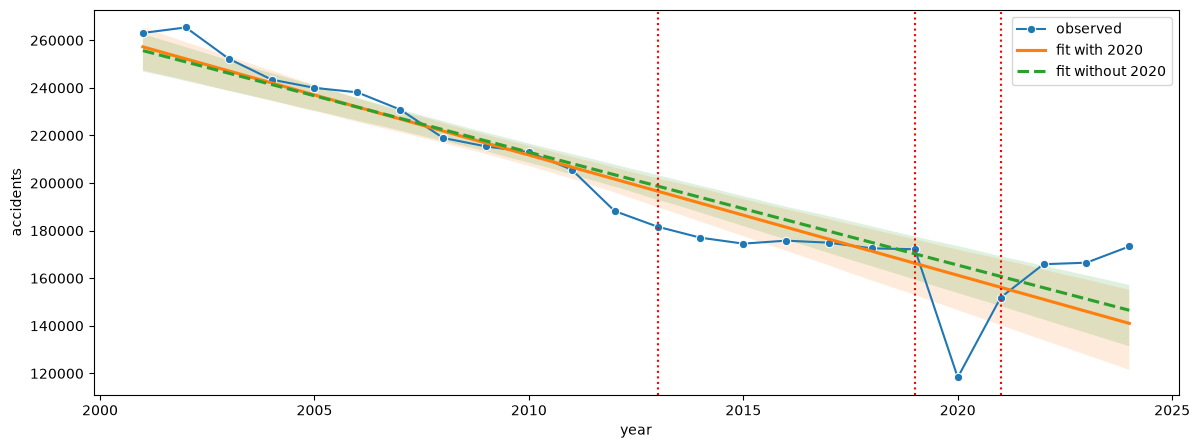

2024 vs 2019: +0.7%


In [61]:
fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=national, x='year', y='accidents', marker='o', ax=ax, label='observed')

# regplot can help us visualize better the difference in linear regression between the 2020-inclusive ed exclusive df
sns.regplot(data=national, x='year', y='accidents', scatter=False, ax=ax, label='fit with 2020')
sns.regplot(data=national[national.year != 2020], x='year', y='accidents',
            scatter=False, ax=ax, label='fit without 2020', line_kws={'ls': '--'})

# adding vertical lines in corrispondance of the three phases (see later in the document)
ax.axvline(x=2013, color='red', linestyle=':')
ax.axvline(x=2019, color='red', linestyle=':')
ax.axvline(x=2021, color='red', linestyle=':')
ax.legend()
plt.show()

# 2024 vs 2019 to check if the years are mostly on par
print(f"2024 vs 2019: {national.set_index('year')['accidents'][2024] / national.set_index('year')['accidents'][2019] - 1:+.1%}")

The trend is still visibile without 2020. The slope barely changes (-2.3% vs -2.5% per year), and the p-value is small in both cases. The year 2020 is an outlier that makes the decline look slightly steeper. Excluding it  for periods and trends calcs is the right default, so I'll keep `exclude_2020=True` and probably we might as well cut off 2021.

But looking at the graph we can also see a distribution in three "phases", as made evident by the three vertical red lines:

In [62]:
phases = {'2001-2012': (2001, 2012), '2013-2019': (2013, 2019), '2021-2024': (2021, 2024)}

pd.DataFrame({name: trend(national[national.year.between(a, b)])
              for name, (a, b) in phases.items()})

,2001-2012,2013-2019,2021-2024
slope,-6.458769e+03,-1321.178571,6510.300000
pct_per_year,-2.793485e+00,-0.752692,3.959717
r2,9.717627e-01,0.797280,0.868664
pvalue,4.470835e-09,0.006800,0.067979


* **2001–2012**: strong decline. About -2.8% per year with a very good fit (r2 0.97) and a tiny p-value. This is the main source of the long-term drop.
* **2013–2019**: slow decline. About -0.75% per year and still significant (p = 0.007). It’s not fully flat, but the improvement has slowed down a lot.
* **2020**: not included.
* **2021–2024**: rising, but not proven. About +4% per year, but p = 0.068 with only 4 points, so it isn’t significant at 0.05. More important, 2024 seems almost on par with the 2019 level. Probably a return to pre-Covid baseline more than an actual upwards trend.

In [63]:
# regression in "phases" on 2001-2019 (pre-COVID) to check for trand change
d = national[national.year.between(2001, 2019)].copy()
d['t'] = d.year - 2001                              # years since 2001 (overall trend)
d['after'] = (d.year >= 2013).astype(int)           # 1 from 2013 on: allows a jump in level
d['t_after'] = d['after'] * (d.year - 2013)         # years since 2013: allows a change in slope

# ordinary least squares regression with the three terms plus a constant
m = sm.OLS(d['accidents'], sm.add_constant(d[['t', 'after', 't_after']])).fit()
m.summary().tables[1]
# H0 = no change in slope in 2013.
# A small p-value on t_after rejects H0

,coef,std err,t,P>|t|,[0.025,0.975]
const,2.667e+05,1910.975,139.579,0.000,2.63e+05,2.71e+05
t,-6458.7692,294.287,-21.947,0.000,-7086.026,-5831.512
after,-9735.6548,3231.255,-3.013,0.009,-1.66e+04,-2848.399
t_after,5137.5907,727.260,7.064,0.000,3587.474,6687.708


The slope change in 2013 is significant (p-value of `t_after` ≈ 0.000). The slope after 2013 is −6459 + 5138 = −1321 accidents per year, the same value found in the phases table. The regression therefore confirms the change in trend that we can see in the chart. The model also finds a small drop in level in 2013 (`after`, p ≈ 0.009).

*NB: yearly accident counts are autocorrelated (each year resembles the previous one), so regression p-values should be read as indicative rather than precise.*

**My conclusion**: accidents declined nationally over 2001–2024, but most of the gain happened before 2013. The decline has stalled since then, and current levels are back where they were in 2019. Future reasoning will therefore focus on the 2022–2024 block, which fully excludes the COVID effect, keeping in mind that we are in a "plateau" era.

### Regional trends

Let's see if the pattern exist also on the regional level

In [64]:
# first we need to create a dict of region names, which are in official ISTAT coding
# the order goes roughly from north to south, which is useful to visualize the classic difference north/south of italy
# insert appropriate meme: https://www.reddit.com/r/EveryMapOfItaly/

region_names = {1: 'Piemonte', 2: "Valle d'Aosta", 3: 'Lombardia', 4: 'Trentino-AA',
                5: 'Veneto', 6: 'Friuli-VG', 7: 'Liguria', 8: 'Emilia-Romagna',
                9: 'Toscana', 10: 'Umbria', 11: 'Marche', 12: 'Lazio', 13: 'Abruzzo',
                14: 'Molise', 15: 'Campania', 16: 'Puglia', 17: 'Basilicata',
                18: 'Calabria', 19: 'Sicilia', 20: 'Sardegna'}

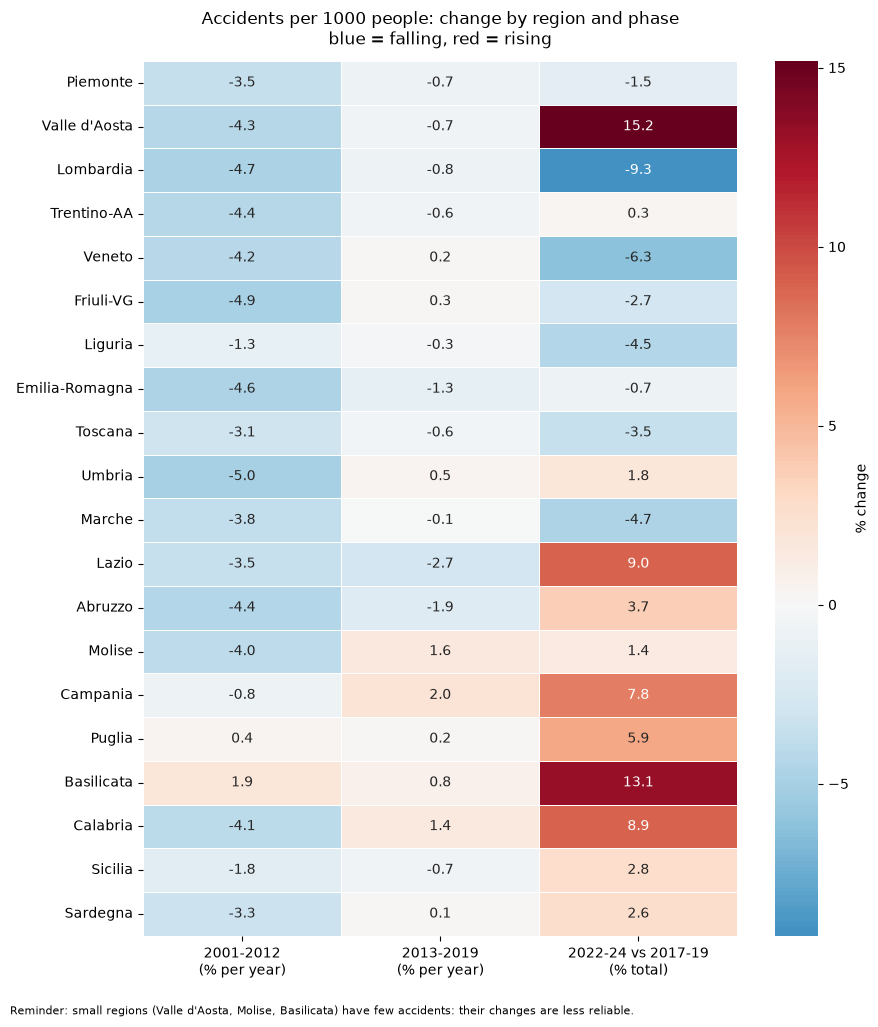

In [65]:
# the regional variation of the aggregate dataframe
regional  = aggregate_yearly(traffic, ['region_code'])

# the following are the phases where we fit a trend line (enough years for a reliable slope), as found before
trend_phases = {'2001-2012\n(% per year)': (2001, 2012),
                '2013-2019\n(% per year)': (2013, 2019)}

rows = [] # one dict per region, turned into a DataFrame at the end

# for cycle over every regions: 'region' is the code, 'g' is that region's yearly rows
for region, g in regional.groupby('region_code'):
    row = {'region': region_names[int(region)]} # we cast it as int (i believe it is float right now), but better to cast it to avoid errors

     # for cycle for each phase: keep only its years, fit the trend on the rate, and store average % change per year
    for name, (a, b) in trend_phases.items():
        row[name] = trend(g[g.year.between(a, b)], col='accidents_per_1000people')['pct_per_year']

    # last phase is too short for a slope ( covers jsut 3 years), so we compare levels instead:
    # average rate after COVID (2022-24) vs average rate before COVID (2017-19)
    pre  = g[g.year.between(2017, 2019)]['accidents_per_1000people'].mean()
    post = g[g.year.between(2022, 2024)]['accidents_per_1000people'].mean()
    row['2022-24 vs 2017-19\n(% total)'] = (post / pre - 1) * 100 # total % change

    rows.append(row)

# build the table: one row per region and one column per phase
region_phases = pd.DataFrame(rows).set_index('region')

# here we set up the heatmap
fig, ax = plt.subplots(figsize=(9, 10))
sns.heatmap(region_phases, annot=True, fmt='.1f', # write annotation per cell, 0,1 pct point
            cmap='RdBu_r', # a red-blue shift reversed
            center=0, linewidths=0.5, cbar_kws={'label': '% change'}, ax=ax)
ax.set_title('Accidents per 1000 people: change by region and phase\n'
             'blue = falling, red = rising', pad=12)
ax.set_xlabel('')
ax.set_ylabel('')
ax.tick_params(axis='x', rotation=0)

# just to make it complete, a footnote that warns that small regions have unstable percentages (also reminder for me)
plt.figtext(0.01, -0.02, "Reminder: small regions (Valle d'Aosta, Molise, Basilicata) have few accidents: "
            "their changes are less reliable.", fontsize=8, ha='left')
plt.tight_layout()
plt.show()

Each number is a percentage change in the accident rate (accidents per 1000 residents) for that region.

Each column measures it differently:

* **Columns 1 and 2 (% per year)**: the average yearly change in that phase, taken from the slope of a straight line fitted through the years. (e.g.: Lombardia at -4.7 in 2001–2012 means its rate fell by about 4.7% average each year, while Campania +2.0 in 2013–2019 means its rate rose by about 2% each year)
* **Column 3 (% total)**: a single before/after comparison, with no per-year averaging. It compares the average rate in 2022–2024 with the average rate in 2017–2019 (e.g.: Lombardia at -9.3 means the recent rate is 9.3% lower than before COVID, while Campania 7.8 means its rate is 7,8% worse than before COVID).

So, the colors show direction of change (blue = fewer accidents per person, red = more), and the number shows how strong the change is. Is important to stress that they are not a measure of how dangerous a region is. A region can be red but still have a low rate overall. Since this show a shift in rate of accidents per person we also have to account for internal migration:

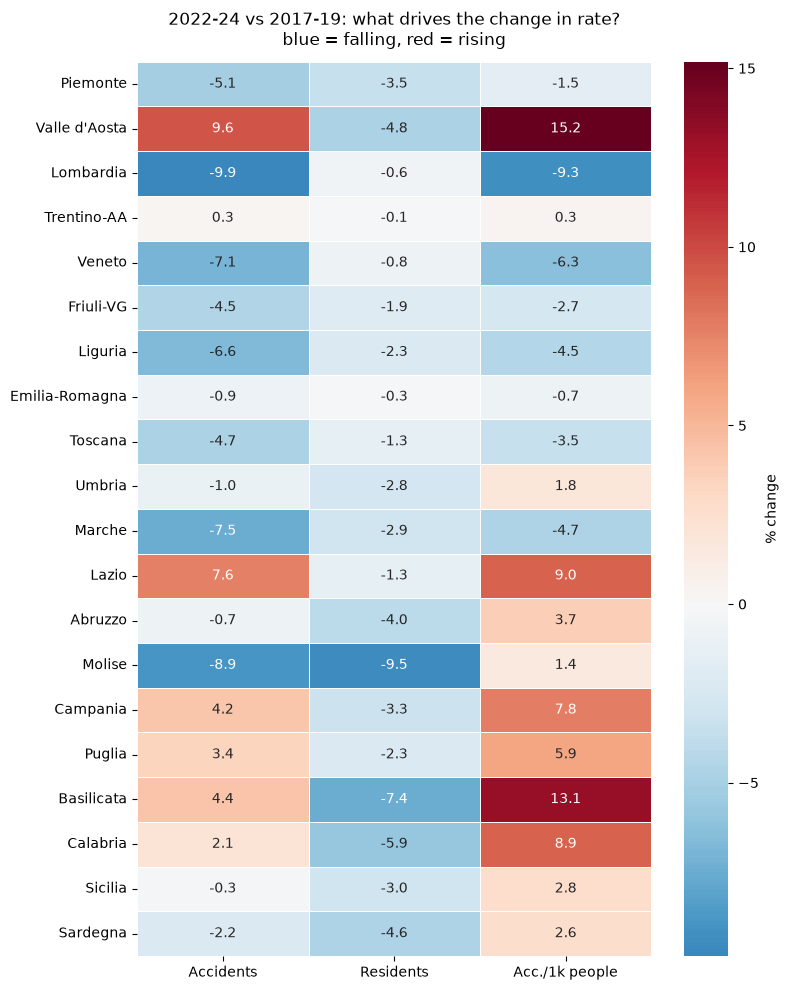

In [66]:
# we define a function representing the % change of any column between pre-COVID (2017-19) and post-COVID (2022-24) averages
def pct_change(g, col): # g = yearly rows of one group, col = column to compare
    pre  = g[g.year.between(2017, 2019)][col].mean()
    post = g[g.year.between(2022, 2024)][col].mean()
    return (post / pre - 1) * 100

rows = []

# for each region, compare the two parts of the rate separately:
# rate = accidents / residents, so rate change ≈ accidents change - residents change
for region, g in regional.groupby('region_code'):
    rows.append({'region': region_names[int(region)],
                 'Accidents': pct_change(g, 'accidents'),
                 'Residents': pct_change(g, 'residents'),
                 'Acc./1k people': pct_change(g, 'accidents_per_1000people')})

drivers = pd.DataFrame(rows).set_index('region')

# same heatmap style as cell 1, so the two charts can be visually compared
fig, ax = plt.subplots(figsize=(8, 10))
sns.heatmap(drivers, annot=True, fmt='.1f',
            cmap='RdBu_r', # NB: the "worst" data on the 'residents' column will not show as clearly since the direction would be inverse
            center=0, linewidths=0.5, cbar_kws={'label': '% change'}, ax=ax)
ax.set_title('2022-24 vs 2017-19: what drives the change in rate?\n'
             'blue = falling, red = rising', pad=12)
ax.set_xlabel('')
ax.set_ylabel('')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

### Conclusions: national and regional trends

**National level**
* Road accidents in Italy fell substantially between 2001 and 2024, but not at a steady pace:
  * **2001–2012:** strong decline, about **-2.8% per year**
  * **2013–2019:** much slower decline, about **-0.75% per year**
  * **2022–2024:** back around the pre-COVID level (2024 accidents only **+0.7%** vs 2019)
* **Important outlier: 2020** The long-term trend holds with or without it (-2.5% vs -2.3% per year), so 2020 is excluded from trend calculations.

**Regional level**
* The national decline is **driven by the North and Center**: most of these regions fell by about 4% per year
  until 2012 and are now **below** pre-COVID levels (Lombardia -9.3%, Veneto -6.3%).
* **North/Center:** the highest current accident rates, mostly minor accidents in dense towns; rates are stable or improving, with the exception of Lazio.
* **South/Islands:** lower rates, but a real increase in accidents in Campania, Puglia, Basilicata and Calabria (Sicilia and Sardegna rise only because population fell), and accidents are more often deadly in rural areas.
* The **South (+Lazio) does not follow the national trend**: weaker or no early decline (Campania, Puglia, Basilicata)
  and rates now **above** pre-COVID levels. But, splitting the rate into accidents and residents shows two different situations:
  * **Real increase in accidents:** Lazio (+7.6%), Campania (+4.2%), Puglia (+3.4%), Basilicata (+4.4%), Calabria (+2.1%)
  * **Rate up only because population fell:** Abruzzo, Sicilia, Sardegna, Molise. Accidents are flat or down.
  * **Overall**: there might be an effect of the internal migration from south to north, the data cannot show it right now.

**Business-side focus point**
The regions where road safety is actually getting worse are **Lazio, Campania, Puglia, Basilicata and Calabria**. These are the first candidates for investment, and the analysis continues at the province and municipality level (_Power BI dashboard_).

**Known limitation**: Small regions (Valle d'Aosta, Molise, Basilicata) have fewer accidents and smaller population (percentage are less reliable)

# Municipalities: where are the riskiest ones?

The regional analysis showed a North/South divide. Here we move to single municipality to check.  
We will focus on the 2022–2024 years, since we have established (on the national level) that is more useful.

The main focus are:
* How do municipalities compare density and accident rate, by macro area?
* Can we group municipalities with similar risk profiles?
* Do the riskiest groups concentrate in a (or more) specific part(s) of Italy?

In [67]:
# our dear aggregate function by area code and for the 2022-2024 period
municipalities = aggregate_period(traffic, 2022, 2024, group_by=('area_code',))

# attach the most recent name and codes of each comune to help us visualize
latest = (traffic.sort_values('year').groupby('area_code')
          [['area_name', 'province_code', 'region_code',
            'is_province_capital', 'is_region_capital']].last().reset_index())
municipalities = municipalities.merge(latest, on='area_code', how='left')

# drop municipalities without region or population (cannot be placed or compared)
municipalities = municipalities.dropna(subset=['region_code', 'residents']).copy()

# lets' imputate macro areas from the ISTAT region codes (1-8 North, 9-12 Center, 13-18 South, 19-20 Islands)
# NB: ISTAT's macro area code was in area_raw but dropped during cleaning; it is rebuilt here from region_code
def macro_area(code):
    if code <= 8:
        return 'North'
    if code <= 12:
        return 'Center'
    if code <= 18:
        return 'South'
    return 'Islands'

municipalities['macro_area'] = municipalities['region_code'].astype(int).apply(macro_area)
municipalities['region'] = municipalities['region_code'].astype(int).map(region_names)
area_order = ['North', 'Center', 'South', 'Islands']

Now we can proceed with a scatterplot to better look at how the rate of accidents per 1000 people per year, compares with the density of population.

Some caveats:

* Density spans several orders of magnitude (from about 10 to over 10,000 residents per kmq), so it is shown on a log scale to keep sparse and dense municipalities readable._

* Small municipalities unreliable for comparison and clustering: with so few accidents, one single event more (or less) can change the rate by a lot. We'll filter the municipalities.

Municipalities kept: 1914 of 7910


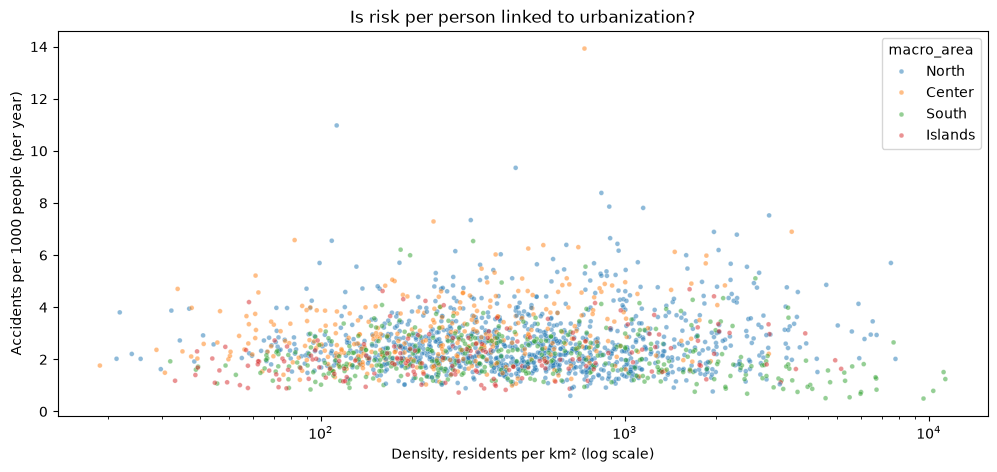

In [ ]:
min_residents = 5000   # minimum residents for a municipality to be kept
min_accidents = 30     # minimum accidents in 3 years (2022-2024)

# keep only municipalities large enough to have stable rates
muni_filtered = municipalities[(municipalities['residents'] >= min_residents) &
                               (municipalities['accidents'] >= min_accidents)].copy()

# lets print how much we have filtered out
print(f"Municipalities kept: {len(muni_filtered)} of {len(municipalities)}")

# scatterplot time
fig, ax = plt.subplots(figsize=(12, 5))
sns.scatterplot(data=muni_filtered, x='density', y='accidents_per_1000people',
                hue='macro_area', hue_order=area_order, s=12, alpha=.5, ax=ax)
ax.set_xscale('log')
ax.set_xlabel('Density, residents per kmq (log scale)')
ax.set_ylabel('Accidents per 1000 people (per year)')
ax.set_title('Is risk per person linked to urbanization?')
plt.show()

Density seems to show no clear link with the accident rate: the cloud is flat across all levels of urbanization. We can see however a slight separation in the distribution of macro areas: northern and central municipalities sit in the upper part more frequently, while southern and island municipalities are mostly in the lower part, including the densest southern comuni. The South therefore starts from lower rates, even though it is the area where rates are rising (see regional analysis above).

In [69]:
# log scale for density and rate
# both are skewed so the log spreads them more evenly
muni_filtered['log_density'] = np.log10(muni_filtered['density'])
muni_filtered['log_rate'] = np.log10(muni_filtered['accidents_per_1000people'])

# two sets of variables to compare
features_a = ['log_rate', 'log_density']                              # A: rate + density
features_b = ['log_rate', 'log_density', 'killed_per_100accidents']   # B: A + severity

In [70]:
def run_kmeans(df, features, k, seed=0):
    # runs k-means on the chosen features and returns the cluster of each municipality
    X = df[features]
    X = (X - X.mean()) / X.std()            # standardize: every variable gets mean 0 and std 1
    # minit='++' picks smart starting points; seed makes the result repeatable
    centroids, labels = kmeans2(X.to_numpy(), k, minit='++', seed=seed)
    return labels, X

def inertia(X, labels):
    # total squared distance of each municipality from the center of its cluster
    # lower = tighter clusters; used to choose k in the elbow chart
    total = 0
    for c in np.unique(labels):
        group = X[labels == c]                                  # municipalities in cluster c
        total += ((group - group.mean()) ** 2).to_numpy().sum() # distance from the cluster center
    return total

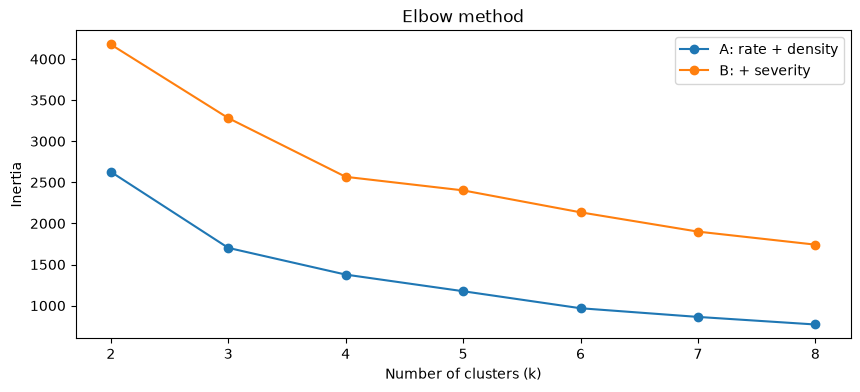

In [71]:
# elbow method, run k-means for k from 2 to 8 and plots inertia for both feature sets
ks = range(2, 9)
fig, ax = plt.subplots(figsize=(10, 4))
for name, feats in [('A: rate + density', features_a), ('B: + severity', features_b)]:
    scores = []
    for k in ks:
        labels, X = run_kmeans(muni_filtered, feats, k)
        scores.append(inertia(X, labels))
    ax.plot(list(ks), scores, marker='o', label=name)
# look for the point where the line stops dropping fast
ax.set_xlabel('Number of clusters (k)')
ax.set_ylabel('Inertia')
ax.set_title('Elbow method')
ax.legend()
plt.show()

In [72]:
K = 4   # chosen from the elbow chart as the titular "elbow"

# run both versions and store the cluster of each municipality as new columns
labels_a, _ = run_kmeans(muni_filtered, features_a, K)
labels_b, _ = run_kmeans(muni_filtered, features_b, K)
muni_filtered['cluster_a'] = labels_a
muni_filtered['cluster_b'] = labels_b

In [73]:
def profile(col):
    # median values of each cluster: what a "typical" municipality in it looks like
    p = (muni_filtered.groupby(col)[['accidents_per_1000people', 'density',
                                     'killed_per_100accidents', 'residents']]
         .median().round(2))
    p['n_municipalities'] = muni_filtered[col].value_counts()          # size of each cluster
    return p.sort_values('accidents_per_1000people', ascending=False)  # riskiest first

print('Version A (rate + density)')
display(profile('cluster_a'))
print('Version B (rate + density + severity)')
display(profile('cluster_b'))

Version A (rate + density)


,accidents_per_1000people,density,killed_per_100accidents,residents,n_municipalities
cluster_a,,,,,
0,3.64,1078.39,1.02,24270.83,304
2,2.90,264.06,2.08,11808.83,578
1,1.86,161.52,3.03,9418.33,493
3,1.77,852.15,1.67,12804.67,539


Version B (rate + density + severity)


,accidents_per_1000people,density,killed_per_100accidents,residents,n_municipalities
cluster_b,,,,,
0,3.58,721.45,1.15,20694.00,484
3,2.41,186.89,2.38,10156.67,673
1,1.84,168.75,7.14,8411.67,191
2,1.72,776.81,1.62,12315.83,566


In [74]:
# how many municipalities end up in each A/B cluster pair:
# a large number in one cell means the two versions agree on that group
pd.crosstab(muni_filtered['cluster_a'], muni_filtered['cluster_b'])

cluster_b,0,1,2,3
cluster_a,,,,
0,301,1,2,0
1,0,137,61,295
2,168,31,4,375
3,15,22,499,3


The four clusters can be described as:
* **Urban, frequent but minor accidents** (A0 / B0): dense, larger towns with the highest accident rate (~3.6 per 1000) but the lowest severity (~1 death per 100 accidents).
* **Semi-rural, medium rate** (A2 / B3): medium density, medium rate and severity.
* **Rural, few but serious accidents** (A1 / B1): sparse, smaller municipalities with the lowest rate but the highest severity. Adding severity (version B) isolates the most extreme group: 191 municipalities with ~7 deaths per 100 accidents, about three times the others.
* **Dense, low rate** (A3 / B2): dense municipalities with low rates and low severity.

The urban and dense groups are almost identical in both versions; severity mainly splits the rural group.

## Do the riskiest clusters concentrate in a specific part of Italy?
For each cluster we look at the share of municipalities coming from each macro area, and compare it with the share among all filtered municipalities (baseline). A cluster is "southern" only if its share of southern municipalities is clearly above the baseline.

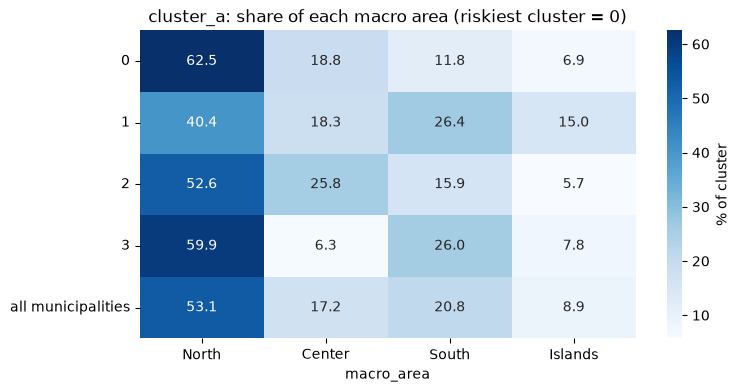

Regions by share of municipalities in the riskiest cluster (cluster_a = 0):


,n_municipalities,pct_in_risky
region,,
Liguria,43,51.2
Lombardia,356,26.7
Marche,63,23.8
Toscana,136,22.8
Abruzzo,41,17.1
Piemonte,95,15.8
Sicilia,126,15.1
Emilia-Romagna,189,13.2
Campania,155,12.9


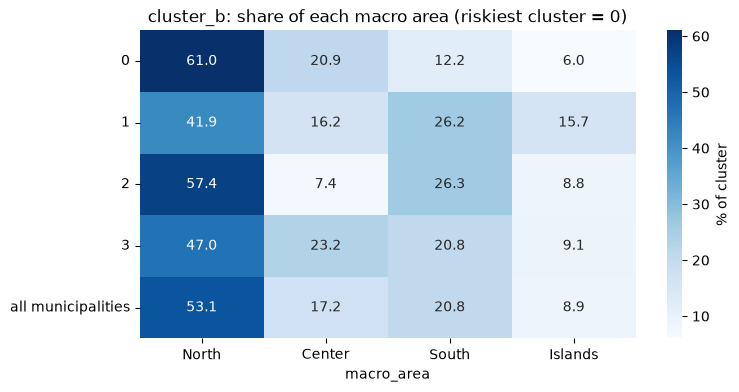

Regions by share of municipalities in the riskiest cluster (cluster_b = 0):


,n_municipalities,pct_in_risky
region,,
Liguria,43,76.7
Toscana,136,40.4
Marche,63,36.5
Lombardia,356,33.4
Abruzzo,41,31.7
Emilia-Romagna,189,28.0
Piemonte,95,23.2
Trentino-AA,37,21.6
Friuli-VG,49,20.4


In [75]:
def macro_check(col):
    # the riskiest cluster is the first row of the profile (highest median rate)
    risky = profile(col).index[0]

    # share of each macro area inside each cluster (each row sums to 100%)
    share = (pd.crosstab(muni_filtered[col], muni_filtered['macro_area'], normalize='index')
             .mul(100).round(1)[area_order])

    # baseline: share of each macro area among all filtered municipalities
    share.loc['all municipalities'] = (muni_filtered['macro_area']
                                       .value_counts(normalize=True).mul(100).round(1)[area_order])

    # heatmap: compare each cluster row with the baseline row at the bottom
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.heatmap(share, annot=True, fmt='.1f', cmap='Blues',
                cbar_kws={'label': '% of cluster'}, ax=ax)
    ax.set_title(f'{col}: share of each macro area (riskiest cluster = {risky})')
    ax.set_ylabel('')
    plt.show()

    # regions: share of each region's municipalities that fall in the riskiest cluster
    # (a share, not a count, so regions with many municipalities like Lombardia are not favored)
    by_region = (muni_filtered.assign(in_risky=muni_filtered[col] == risky)
                 .groupby('region')
                 .agg(n_municipalities=('in_risky', 'size'),
                      pct_in_risky=('in_risky', 'mean')))
    by_region['pct_in_risky'] = (by_region['pct_in_risky'] * 100).round(1)
    print(f'Regions by share of municipalities in the riskiest cluster ({col} = {risky}):')
    display(by_region[by_region['n_municipalities'] >= 20].sort_values('pct_in_risky', ascending=False))


macro_check('cluster_a')
macro_check('cluster_b')

# Conclusions: municipalities

**Density and risk**
* Density shows no clear link with the accident rate: risk per person is similar in sparse and dense municipalities.
* Northern and central municipalities tend to have higher rates; southern and island municipalities lower ones.

**Clusters (2022–2024, municipalities with 5,000+ residents and 30+ accidents)**
* The riskiest cluster by rate is made of dense, larger towns with frequent but mostly minor accidents. It is over-represented in the North (62% vs 53% baseline) and under-represented in the South (12% vs 21%).
* Liguria stands out (about half of its municipalities in this cluster, 77% in version B), followed by Toscana, Marche and Lombardia.
* Southern and island municipalities are over-represented in the rural cluster: lowest rates, but the highest severity. In version B, a small group of 191 rural municipalities reaches almost 7 deaths per 100 accidents.
* The macro area and regional patterns are the same in both versions, so the result does not depend on adding severity.

**What this means for the North/South question**
Combined with the regional analysis, there are two different pictures of risk:
* **North/Center:** the highest current accident rates, mostly minor accidents in dense towns; rates are stable or improving, with the exception of Lazio.
* **South/Islands:** lower rates, but a real increase in accidents in Campania, Puglia, Basilicata and Calabria (Sicilia and Sardegna rise only because population fell), and accidents are more often deadly in rural areas.

For the business premise, these point to two investment logics: (1) reducing the number of accidents where they are most frequent (urban North/Center), or (2) preventing serious accidents where conditions are getting worse (rural South and Islands). The dashboard should help decide.

**Left to Power BI**
* Ranking of the municipalities in the riskiest clusters (urban high-rate and rural high-severity), with filters by region and province
* Map of municipalities by cluster
* Trend of single municipalities over time



**Known limitations**
* Clusters split a continuous distribution forming "degrees" not actual grouping.
* Severity is noisy due to low numbers overall (30–60 accidents in 3 years, 7 deaths per 100 accidents = only 2–4 deaths per municipality).
* In tourist areas such as the Ligurian or Toscany coast, the rate per resident may be inflated by non-resident traffic.
* Very low rates in some dense municipalities could partly reflect under-reporting, which the data cannot separate.

In [76]:
# cluster names from the profile tables, so it's more readable on PBI
cluster_a_names = {0: 'Urban, frequent minor accidents', 2: 'Semi-rural, medium rate',
                   1: 'Rural, few but serious', 3: 'Dense, low rate'}
muni_filtered['cluster'] = muni_filtered['cluster_a'].map(cluster_a_names)

# one row per region
dim_region = pd.DataFrame({'region_code': list(region_names.keys()),
                           'region_name': list(region_names.values())})
dim_region['macro_area'] = dim_region['region_code'].apply(macro_area)

# trend per phase and pre/post-COVID change
phases_cols = region_phases.rename(columns={
    '2001-2012\n(% per year)': 'rate_trend_2001_2012_pct_per_year',
    '2013-2019\n(% per year)': 'rate_trend_2013_2019_pct_per_year',
    '2022-24 vs 2017-19\n(% total)': 'rate_change_2022_24_vs_2017_19_pct'})

# accidents and residents change
drivers_cols = drivers[['Accidents', 'Residents']].rename(columns={
    'Accidents': 'accidents_change_2022_24_vs_2017_19_pct',
    'Residents': 'residents_change_2022_24_vs_2017_19_pct'})

# both tables are indexed by region name, so we join on it
dim_region = (dim_region
              .merge(phases_cols, left_on='region_name', right_index=True, how='left')
              .merge(drivers_cols, left_on='region_name', right_index=True, how='left'))

In [77]:
# one row per province
# the registry has no province names, so each province is named after its capital municipality.
# some provinces have more than one capital (e.g. Barletta-Andria-Trani, Pesaro e Urbino),
# in that case we take the first one (lowest municipality code) in the most recent year available
capitals = traffic[traffic['is_province_capital']].sort_values(['province_code', 'year', 'area_code'])
latest_capitals = capitals[capitals['year'] == capitals.groupby('province_code')['year'].transform('max')]
province_names = (latest_capitals.groupby('province_code', as_index=False)
                  .first()[['province_code', 'area_name']]
                  .rename(columns={'area_name': 'province_name'}))

# all province codes present in the data, with their last known region
dim_province = (traffic.dropna(subset=['province_code'])
                .sort_values('year')
                .groupby('province_code', as_index=False)
                .agg(region_code=('region_code', 'last')))
dim_province = dim_province.merge(province_names, on='province_code', how='left')

# provinces with no capital in the data (should be rare) get their code as name
dim_province['province_name'] = dim_province['province_name'].fillna(
    'Province ' + dim_province['province_code'].astype(str))
dim_province = dim_province[['province_code', 'province_name', 'region_code']]

In [78]:
# one row per municipality code ever present
dim_municipality = (traffic.sort_values('year')
                    .groupby('area_code', as_index=False)
                    [['area_name', 'province_code', 'region_code']].last())
dim_municipality = dim_municipality.merge(muni_filtered[['area_code', 'cluster']],
                                          on='area_code', how='left')
dim_municipality['kept_in_clustering'] = dim_municipality['cluster'].notna()
# text for the Power BI map (the region helps with municipalities that share a name)
dim_municipality['location'] = (dim_municipality['area_name'] + ', '
                                + dim_municipality['region_code'].map(region_names) + ', Italia')

In [79]:
# one row per year with the periods used in the analysis
dim_year = pd.DataFrame({'year': range(2001, 2025)})

def phase(y):
    # the phases found in the national analysis
    if y <= 2012:
        return '2001-2012 strong decline'
    if y <= 2019:
        return '2013-2019 slow decline'
    if y == 2020:
        return '2020 COVID'
    return '2021-2024 post-COVID'

dim_year['phase'] = dim_year['year'].apply(phase)

In [80]:
# start from all municipalities × years, then attach traffic counts
fact_traffic = pd.merge(
    area_raw[['area_code', 'year', 'residents', 'surface']],
    traffic_raw[['area_code', 'year', 'accidents', 'injured', 'killed']],
    on=['area_code', 'year'], how='left'
)

# keep only the years covered by the traffic data
y_min, y_max = traffic_raw['year'].min(), traffic_raw['year'].max()
fact_traffic = fact_traffic[fact_traffic['year'].between(y_min, y_max)]

# no record = no accidents
fact_traffic[['accidents', 'injured', 'killed']] = fact_traffic[['accidents', 'injured', 'killed']].fillna(0)

In [ ]:
fact_traffic.to_csv('../outputs/fact_traffic.csv', index=False)
dim_municipality.to_csv('../outputs/dim_municipality.csv', index=False)
dim_province.to_csv('../outputs/dim_province.csv', index=False)
dim_region.to_csv('../outputs/dim_region.csv', index=False)
dim_year.to_csv('../outputs/dim_year.csv', index=False)

**Exported tables** (for Power BI)
* `fact_traffic.csv`: accidents, injured, killed, residents and surface, one row per municipality per year (2001–2024)
* `dim_municipality.csv`: municipality name, province, region, cluster, filter flag and map location
* `dim_province.csv`: province code, name (taken from the province capital) and region
* `dim_region.csv`: region code, name, macro area and the regional analysis results (trend per phase, pre/post-COVID change in rate, accidents and residents)
* `dim_year.csv`: year, analysis phase and flags for 2020 and the comparison windows